# Зертханалық жұмыс №3
**Пән:** Компьютерлік көру (Computer Vision)

**Мақсаты:** әр түрлі шу түрлерін синтездеу, оларды бірнеше сүзгімен тазалап PSNR/SSIM арқылы сапасын бағалау, сүзгі параметрлерінің әсерін зерттеу, мерзімді (периодтық) шуды жиілік облысында (FFT) тазарту және нақты түнгі фотоны заманауи алгоритммен (NLM) өңдеу.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.metrics import structural_similarity as ssim
import os

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)
np.random.seed(42)

clean = cv2.imread("images/photo.webp")
print("Түпнұсқа кескін өлшемі:", clean.shape)


Түпнұсқа кескін өлшемі: (320, 234, 3)


## 1-тапсырма: 4 шу түрін 3 деңгейде синтездеу

4 түрлі шу синтезделеді: **Gaussian** (қалыпты үлестірімді аддитивті шу), **Salt & Pepper** (импульстік шу), **Poisson** (фотон санының шектілігінен туындайтын шу, түнгі/төмен жарықты түсірілімдерге тән), **Speckle** (мультипликативті шу, радар/ультрадыбыс кескіндеріне тән). Әрқайсысы үшін 3 деңгей (әлсіз/орташа/күшті) таңдалды.

In [2]:
def add_gaussian_noise(img, sigma):
    noise = np.random.normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float64) + noise, 0, 255).astype(np.uint8)


def add_salt_pepper_noise(img, amount):
    noisy = img.copy()
    h, w = img.shape[:2]
    n = int(amount * h * w)
    ys, xs = np.random.randint(0, h, n // 2), np.random.randint(0, w, n // 2)
    noisy[ys, xs] = 255
    ys, xs = np.random.randint(0, h, n // 2), np.random.randint(0, w, n // 2)
    noisy[ys, xs] = 0
    return noisy


def add_poisson_noise(img, scale):
    """scale аз болған сайын (фотон саны аз) шу күшейеді — түнгі түсірілім эффектісі."""
    img_f = img.astype(np.float64)
    noisy = np.random.poisson(img_f * (scale / 255.0)) / (scale / 255.0)
    return np.clip(noisy, 0, 255).astype(np.uint8)


def add_speckle_noise(img, var):
    noise = np.random.normal(0, var ** 0.5, img.shape)
    noisy = img.astype(np.float64) + img.astype(np.float64) * noise
    return np.clip(noisy, 0, 255).astype(np.uint8)


NOISE_GENERATORS = {
    "Gaussian": add_gaussian_noise,
    "Salt & Pepper": add_salt_pepper_noise,
    "Poisson": add_poisson_noise,
    "Speckle": add_speckle_noise,
}

# Әр шу түрі үшін 3 деңгей (низкий/орташа/жоғары) параметрлері
NOISE_LEVELS = {
    "Gaussian":       {"Әлсіз (σ=10)": 10, "Орташа (σ=25)": 25, "Күшті (σ=50)": 50},
    "Salt & Pepper":  {"Әлсіз (1%)": 0.01, "Орташа (3%)": 0.03, "Күшті (6%)": 0.06},
    "Poisson":        {"Әлсіз (scale=60)": 60, "Орташа (scale=20)": 20, "Күшті (scale=8)": 8},
    "Speckle":        {"Әлсіз (var=0.02)": 0.02, "Орташа (var=0.1)": 0.1, "Күшті (var=0.3)": 0.3},
}

noisy_images = {}  # noisy_images[noise_type][level_label] = image
for noise_type, gen_fn in NOISE_GENERATORS.items():
    noisy_images[noise_type] = {}
    for level_label, param in NOISE_LEVELS[noise_type].items():
        noisy_images[noise_type][level_label] = gen_fn(clean, param)

print("Барлық шу түрлері мен деңгейлері синтезделді:")
for noise_type in noisy_images:
    print(f"  {noise_type}: {list(noisy_images[noise_type].keys())}")


Барлық шу түрлері мен деңгейлері синтезделді:
  Gaussian: ['Әлсіз (σ=10)', 'Орташа (σ=25)', 'Күшті (σ=50)']
  Salt & Pepper: ['Әлсіз (1%)', 'Орташа (3%)', 'Күшті (6%)']
  Poisson: ['Әлсіз (scale=60)', 'Орташа (scale=20)', 'Күшті (scale=8)']
  Speckle: ['Әлсіз (var=0.02)', 'Орташа (var=0.1)', 'Күшті (var=0.3)']


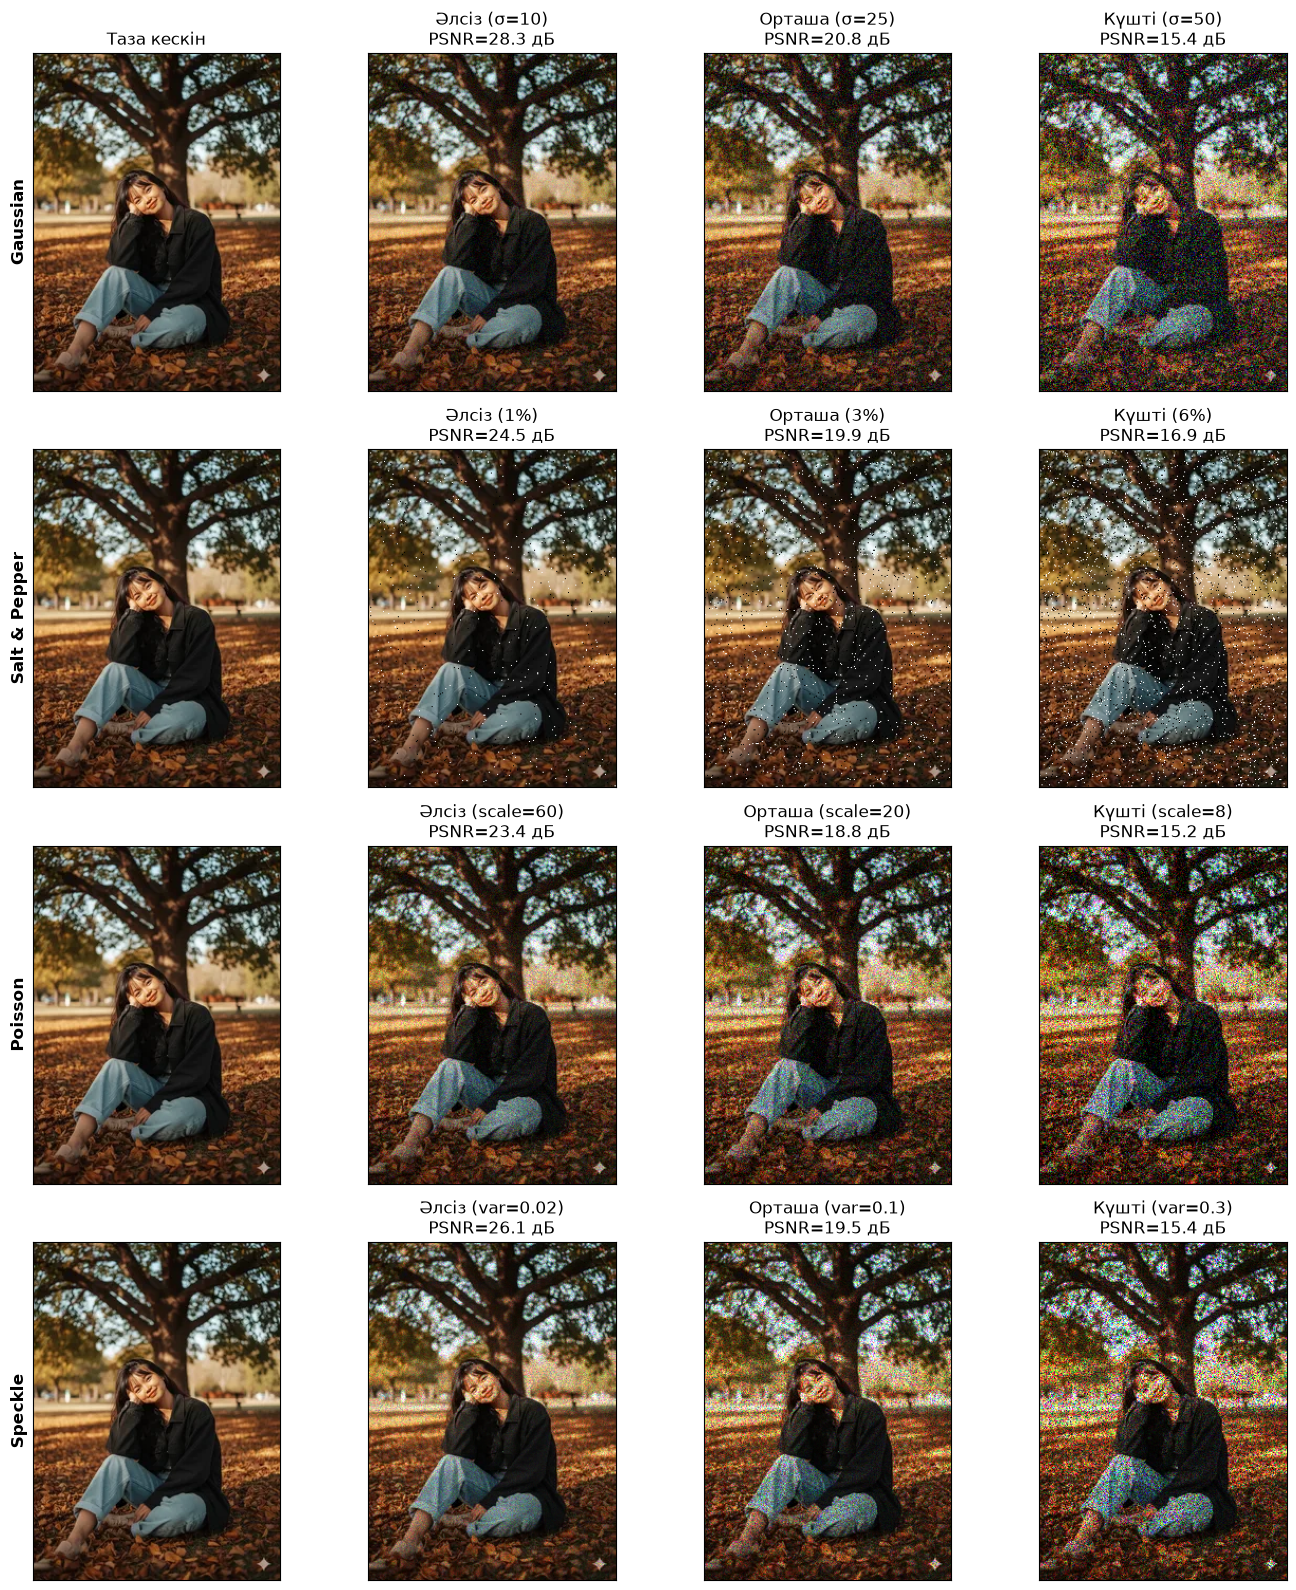

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(14, 16))
for row, (noise_type, levels) in enumerate(noisy_images.items()):
    axes[row, 0].imshow(cv2.cvtColor(clean, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title("Таза кескін" if row == 0 else "")
    axes[row, 0].set_ylabel(noise_type, fontsize=12, fontweight="bold")
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])

    for col, (level_label, noisy_img) in enumerate(levels.items(), start=1):
        psnr = cv2.PSNR(clean, noisy_img)
        axes[row, col].imshow(cv2.cvtColor(noisy_img, cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"{level_label}\nPSNR={psnr:.1f} дБ" if row is not None else "")
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task1_noise_synthesis.png"), bbox_inches="tight", dpi=110)
plt.show()


## 2-тапсырма: 5 сүзгіні қолданып, PSNR және SSIM кестесін толтыру

Әр шу түрі мен деңгейіне 5 сүзгі қолданылады: **Mean**, **Gaussian**, **Median**, **Bilateral**, **NLM (Non-Local Means)**. Әр комбинация үшін PSNR (дБ) және SSIM (0-1 аралығында, 1 — толық сәйкестік) есептеледі.

In [4]:
def apply_filters(img):
    return {
        "Mean": cv2.blur(img, (5, 5)),
        "Gaussian": cv2.GaussianBlur(img, (5, 5), 1.5),
        "Median": cv2.medianBlur(img, 5),
        "Bilateral": cv2.bilateralFilter(img, 9, 75, 75),
        "NLM": cv2.fastNlMeansDenoisingColored(img, None, 10, 10, 7, 21),
    }


def compute_ssim(clean_img, other_img):
    return ssim(clean_img, other_img, channel_axis=2, data_range=255)


psnr_records = []
ssim_records = []

for noise_type, levels in noisy_images.items():
    for level_label, noisy_img in levels.items():
        filtered = apply_filters(noisy_img)
        psnr_row = {"Шу түрі": noise_type, "Деңгей": level_label,
                    "Сүзгісіз": cv2.PSNR(clean, noisy_img)}
        ssim_row = {"Шу түрі": noise_type, "Деңгей": level_label,
                    "Сүзгісіз": compute_ssim(clean, noisy_img)}
        for filt_name, filt_img in filtered.items():
            psnr_row[filt_name] = cv2.PSNR(clean, filt_img)
            ssim_row[filt_name] = compute_ssim(clean, filt_img)
        psnr_records.append(psnr_row)
        ssim_records.append(ssim_row)

psnr_df = pd.DataFrame(psnr_records).set_index(["Шу түрі", "Деңгей"])
ssim_df = pd.DataFrame(ssim_records).set_index(["Шу түрі", "Деңгей"])

print("=== PSNR кестесі (дБ, неғұрлым жоғары болса — соғұрлым жақсы) ===")
display(psnr_df.round(2))


=== PSNR кестесі (дБ, неғұрлым жоғары болса — соғұрлым жақсы) ===


Сүзгісіз   Mean  Gaussian  Median  Bilateral  \
Шу түрі       Деңгей                                                            
Gaussian      Әлсіз (σ=10)          28.32  23.42     25.05   24.09      29.37   
              Орташа (σ=25)         20.78  23.03     24.41   23.28      26.52   
              Күшті (σ=50)          15.40  21.65     22.45   21.70      19.57   
Salt & Pepper Әлсіз (1%)            24.53  23.31     24.87   24.31      23.71   
              Орташа (3%)           19.87  22.90     24.22   24.27      19.73   
              Күшті (6%)            16.94  22.31     23.33   24.17      16.97   
Poisson       Әлсіз (scale=60)      23.42  23.29     24.83   23.59      27.72   
              Орташа (scale=20)     18.82  22.89     24.17   22.51      23.58   
              Күшті (scale=8)       15.16  22.06     22.94   20.40      18.46   
Speckle       Әлсіз (var=0.02)      26.09  23.37     24.98   23.81      28.49   
              Орташа (var=0.1)      19.47  22.85     24.16   22.67      23.22   
              Күшті (var=0.3)       15.43  21.86     22.74   21.32      17.87   

                                   NLM  
Шу түрі       Деңгей                    
Gaussian      Әлсіз (σ=10)       29.27  
              Орташа (σ=25)      22.12  
              Күшті (σ=50)       15.50  
Salt & Pepper Әлсіз (1%)         24.60  
              Орташа (3%)        20.51  
              Күшті (6%)         17.65  
Poisson       Әлсіз (scale=60)   26.78  
              Орташа (scale=20)  19.89  
              Күшті (scale=8)    15.18  
Speckle       Әлсіз (var=0.02)   28.45  
              Орташа (var=0.1)   21.68  
              Күшті (var=0.3)    15.47

In [5]:
print("=== SSIM кестесі (0-1, неғұрлым 1-ге жақын болса — соғұрлым жақсы) ===")
display(ssim_df.round(3))


=== SSIM кестесі (0-1, неғұрлым 1-ге жақын болса — соғұрлым жақсы) ===


Сүзгісіз   Mean  Gaussian  Median  Bilateral  \
Шу түрі       Деңгей                                                            
Gaussian      Әлсіз (σ=10)          0.844  0.719     0.804   0.751      0.875   
              Орташа (σ=25)         0.579  0.681     0.755   0.683      0.802   
              Күшті (σ=50)          0.335  0.591     0.647   0.568      0.495   
Salt & Pepper Әлсіз (1%)            0.871  0.708     0.791   0.777      0.775   
              Орташа (3%)           0.686  0.674     0.748   0.775      0.616   
              Күшті (6%)            0.513  0.633     0.698   0.772      0.462   
Poisson       Әлсіз (scale=60)      0.750  0.713     0.796   0.727      0.854   
              Орташа (scale=20)     0.549  0.689     0.763   0.657      0.757   
              Күшті (scale=8)       0.366  0.641     0.705   0.499      0.552   
Speckle       Әлсіз (var=0.02)      0.883  0.721     0.807   0.752      0.868   
              Орташа (var=0.1)      0.682  0.698     0.779   0.703      0.774   
              Күшті (var=0.3)       0.486  0.659     0.730   0.639      0.622   

                                   NLM  
Шу түрі       Деңгей                    
Gaussian      Әлсіз (σ=10)       0.890  
              Орташа (σ=25)      0.646  
              Күшті (σ=50)       0.340  
Salt & Pepper Әлсіз (1%)         0.837  
              Орташа (3%)        0.689  
              Күшті (6%)         0.530  
Poisson       Әлсіз (scale=60)   0.872  
              Орташа (scale=20)  0.583  
              Күшті (scale=8)    0.367  
Speckle       Әлсіз (var=0.02)   0.917  
              Орташа (var=0.1)   0.778  
              Күшті (var=0.3)    0.505

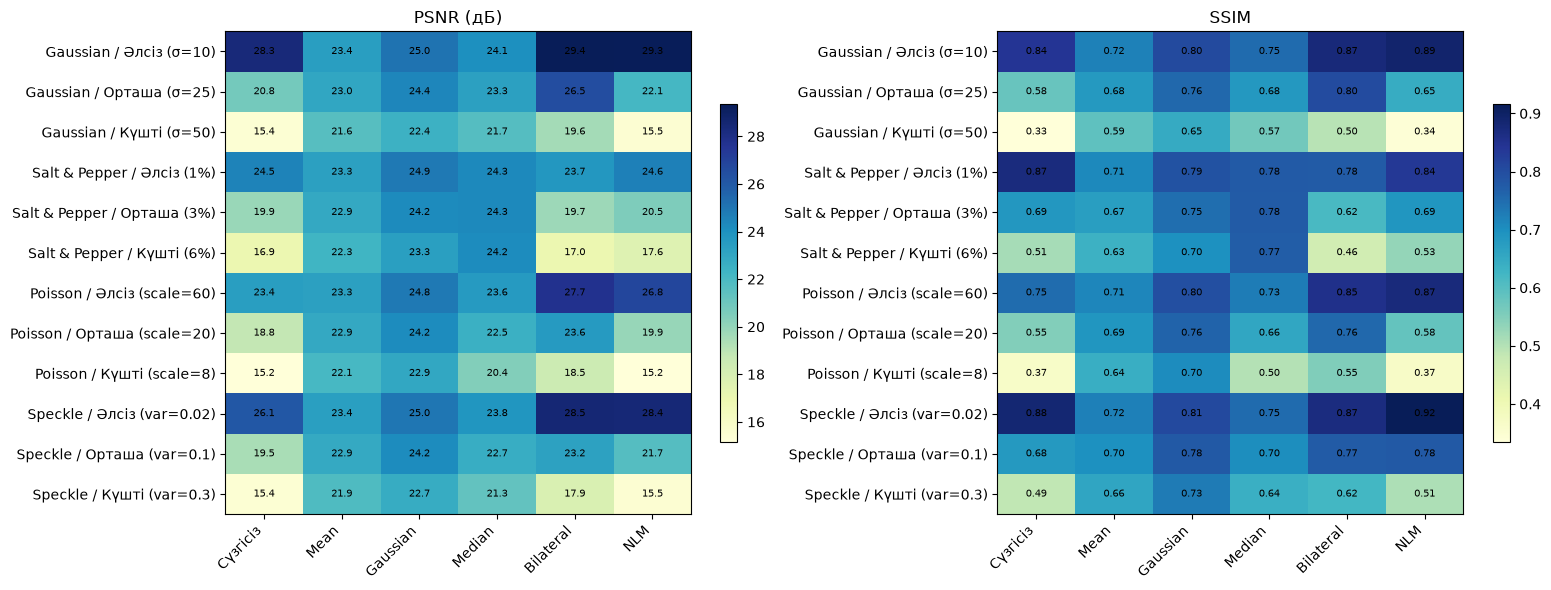


Әр шу/деңгей комбинациясы үшін PSNR бойынша ең жақсы сүзгі:
  Gaussian        Әлсіз (σ=10)         -> Bilateral
  Gaussian        Орташа (σ=25)        -> Bilateral
  Gaussian        Күшті (σ=50)         -> Gaussian
  Salt & Pepper   Әлсіз (1%)           -> Gaussian
  Salt & Pepper   Орташа (3%)          -> Median
  Salt & Pepper   Күшті (6%)           -> Median
  Poisson         Әлсіз (scale=60)     -> Bilateral
  Poisson         Орташа (scale=20)    -> Gaussian
  Poisson         Күшті (scale=8)      -> Gaussian
  Speckle         Әлсіз (var=0.02)     -> Bilateral
  Speckle         Орташа (var=0.1)     -> Gaussian
  Speckle         Күшті (var=0.3)      -> Gaussian


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, df, title, fmt in zip(
    axes, [psnr_df, ssim_df], ["PSNR (дБ)", "SSIM"], ["{:.1f}", "{:.2f}"]
):
    data = df.values
    im = ax.imshow(data, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(len(df.columns)))
    ax.set_xticklabels(df.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(df.index)))
    ax.set_yticklabels([f"{a} / {b}" for a, b in df.index])
    ax.set_title(title)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center", fontsize=7)
    plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task2_psnr_ssim_heatmap.png"), bbox_inches="tight", dpi=110)
plt.show()

best_filters = psnr_df.drop(columns="Сүзгісіз").idxmax(axis=1)
print("\nӘр шу/деңгей комбинациясы үшін PSNR бойынша ең жақсы сүзгі:")
for idx, best in best_filters.items():
    print(f"  {idx[0]:<15} {idx[1]:<20} -> {best}")


**Кестені талдау:** Salt & Pepper шуында деңгей **күшейген сайын** Median сүзгісінің басымдығы айқындала түседі (3% және 6% деңгейде ол PSNR/SSIM бойынша нақты жеңімпаз). Ал өте әлсіз деңгейде (1%) Gaussian/NLM Median-мен шамалас немесе тіпті сәл жоғары нәтиже көрсетуі мүмкін — себебі бұл жағдайда бүлінген пиксель өте аз, әрі медиана сүзгісі таза аймақтарда да әр пикселді жергілікті медианаға ауыстырып, өз бетінше кішкене деталь жоғалтады. Ал Gaussian/Poisson/Speckle (үздіксіз таралған) шуларда **Bilateral** мен **Gaussian** сүзгілері әрдайым Median-нан басым — бұл шу сипатына сай сүзгі таңдаудың маңыздылығын растайды.

## 3-тапсырма: параметрлерді өзгертіп, PSNR графигін салу

Gaussian шуы ($\sigma=25$) үшін үш сүзгінің параметрін өзгерте отырып, PSNR-дың қалай өзгеретінін зерттейміз: **Median** үшін ядро өлшемі, **Gaussian** сүзгісі үшін $\sigma$, **NLM** үшін $h$ (сүзгілеу күші) параметрі.

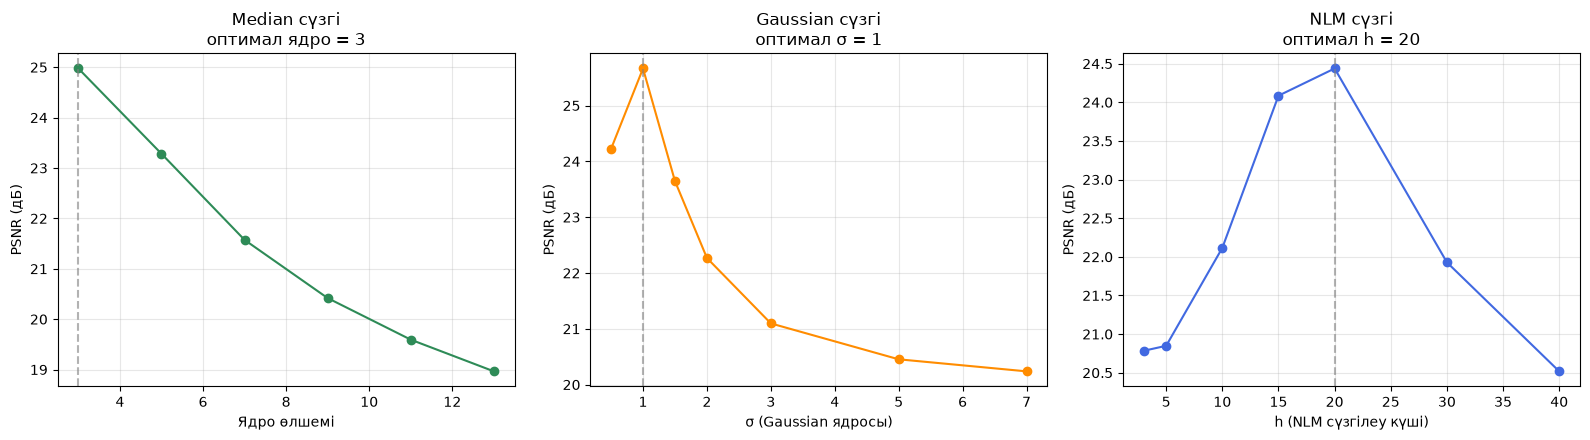

In [7]:
noisy_gauss25 = noisy_images["Gaussian"]["Орташа (σ=25)"]

# 1) Median: ядро өлшемін өзгерту
kernel_sizes = [3, 5, 7, 9, 11, 13]
median_psnr = [cv2.PSNR(clean, cv2.medianBlur(noisy_gauss25, k)) for k in kernel_sizes]

# 2) Gaussian: sigma-ны өзгерту (ядро тұрақты 9x9)
sigmas = [0.5, 1, 1.5, 2, 3, 5, 7]
gauss_psnr = [cv2.PSNR(clean, cv2.GaussianBlur(noisy_gauss25, (9, 9), s)) for s in sigmas]

# 3) NLM: h параметрін өзгерту (сүзгілеу күші)
h_values = [3, 5, 10, 15, 20, 30, 40]
nlm_psnr = [
    cv2.PSNR(clean, cv2.fastNlMeansDenoisingColored(noisy_gauss25, None, h, h, 7, 21))
    for h in h_values
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(kernel_sizes, median_psnr, "o-", color="seagreen")
best_k = kernel_sizes[int(np.argmax(median_psnr))]
axes[0].axvline(best_k, color="gray", linestyle="--", alpha=0.6)
axes[0].set_xlabel("Ядро өлшемі"); axes[0].set_ylabel("PSNR (дБ)")
axes[0].set_title(f"Median сүзгі\nоптимал ядро = {best_k}")
axes[0].grid(alpha=0.3)

axes[1].plot(sigmas, gauss_psnr, "o-", color="darkorange")
best_s = sigmas[int(np.argmax(gauss_psnr))]
axes[1].axvline(best_s, color="gray", linestyle="--", alpha=0.6)
axes[1].set_xlabel("σ (Gaussian ядросы)"); axes[1].set_ylabel("PSNR (дБ)")
axes[1].set_title(f"Gaussian сүзгі\nоптимал σ = {best_s}")
axes[1].grid(alpha=0.3)

axes[2].plot(h_values, nlm_psnr, "o-", color="royalblue")
best_h = h_values[int(np.argmax(nlm_psnr))]
axes[2].axvline(best_h, color="gray", linestyle="--", alpha=0.6)
axes[2].set_xlabel("h (NLM сүзгілеу күші)"); axes[2].set_ylabel("PSNR (дБ)")
axes[2].set_title(f"NLM сүзгі\nоптимал h = {best_h}")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task3_parameter_sweep.png"), bbox_inches="tight", dpi=120)
plt.show()


**Талдау:** үш параметрде де PSNR графигі **бір шыңды (unimodal)** пішінге ие — параметр тым кіші болса, шу жеткілікті басылмайды; тым үлкен болса, сүзгі кескінді артық бұлдырлатып, пайдалы ақпаратты (шеттер мен детальдарды) жояды. Сондықтан әр сүзгі үшін шу деңгейіне сәйкес **оптимал** параметр мәні бар — оны автоматты түрде іздеу (мыс., осындай сипаттағы график арқылы) практикада кеңінен қолданылады.

## 4-тапсырма: периодтық шуы бар кескінді FFT + notch сүзгі арқылы тазарту

Периодтық (мерзімді) шу — электр желісінің кедергісі немесе сканерлеу артефактісі салдарынан пайда болатын синусоидалы құрылым. Ол кеңістіктік облыста көрінбейтін болса да, **Фурье спектрінде** айқын симметриялы шыңдар (пик) түрінде көрінеді, сондықтан оны сол жиілікте "өшіру" арқылы (notch filter) тиімді жоюға болады.

In [8]:
gray = cv2.cvtColor(clean, cv2.COLOR_BGR2GRAY).astype(np.float64)
h, w = gray.shape

# Синтетикалық периодтық шу қосамыз (тік жолақ түріндегі синусоида)
freq = 18  # w бойынша period саны
amplitude = 35
x = np.arange(w)
stripe_pattern = amplitude * np.sin(2 * np.pi * freq * x / w)
periodic_noise = np.tile(stripe_pattern, (h, 1))
noisy_periodic = np.clip(gray + periodic_noise, 0, 255).astype(np.uint8)

# 2D FFT және спектрді центрлеу
f = np.fft.fft2(noisy_periodic)
fshift = np.fft.fftshift(f)
magnitude = 20 * np.log(np.abs(fshift) + 1)

crow, ccol = h // 2, w // 2
print(f"Спектр өлшемі: {fshift.shape}, орталық: ({crow}, {ccol})")
print(f"Күтілетін шыңдар шамамен: ({crow}, {ccol - freq}) және ({crow}, {ccol + freq})")


Спектр өлшемі: (320, 234), орталық: (160, 117)
Күтілетін шыңдар шамамен: (160, 99) және (160, 135)


PSNR (шулы, тазартуға дейін): 20.60 дБ
PSNR (notch сүзгіден кейін): 33.02 дБ


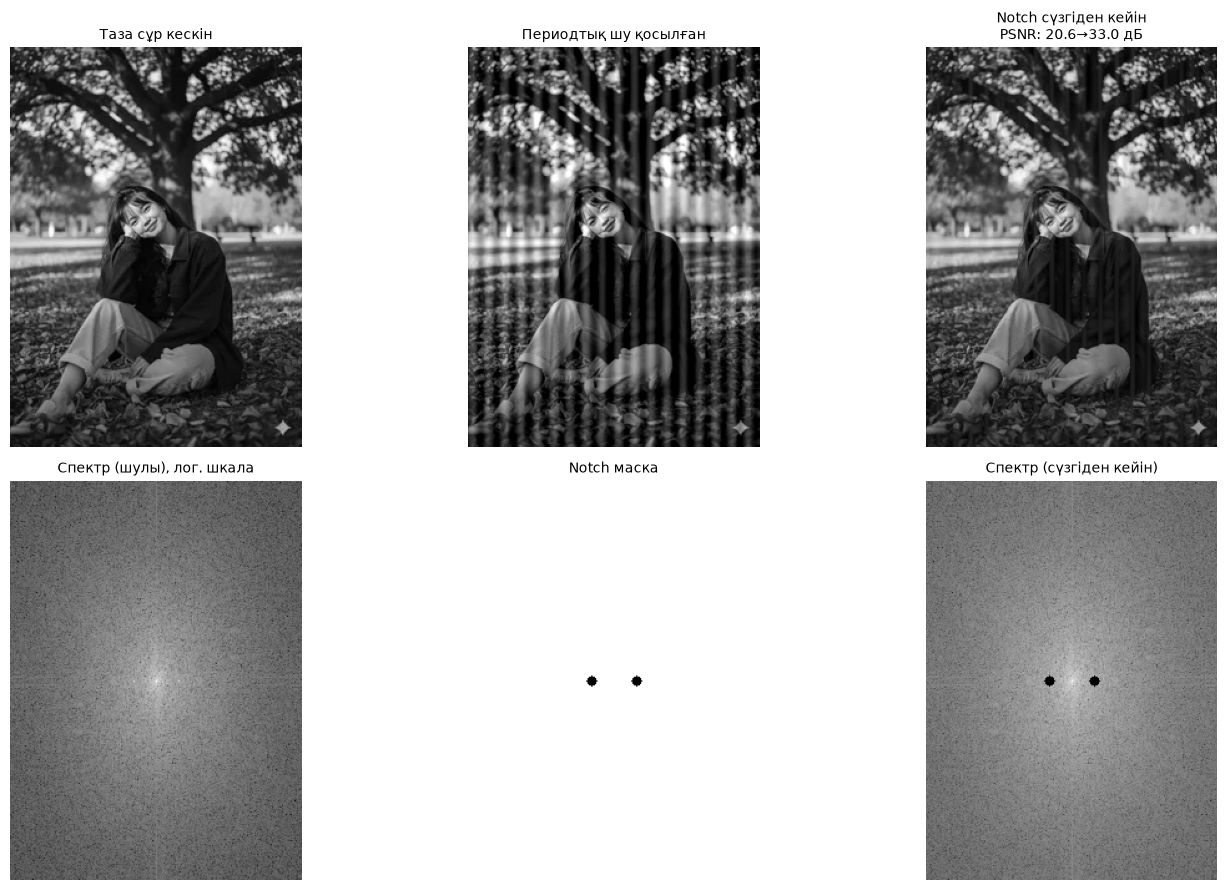

In [9]:
# Notch маска: орталық айналасынан (DC) freq қашықтықтағы екі шыңды өшіреміз
mask = np.ones((h, w), dtype=np.float64)
notch_radius = 4
for (py, px) in [(crow, ccol - freq), (crow, ccol + freq)]:
    yy, xx = np.ogrid[:h, :w]
    dist = np.sqrt((yy - py) ** 2 + (xx - px) ** 2)
    mask[dist <= notch_radius] = 0.0

fshift_filtered = fshift * mask
magnitude_filtered = 20 * np.log(np.abs(fshift_filtered) + 1)

f_ishift = np.fft.ifftshift(fshift_filtered)
img_back = np.fft.ifft2(f_ishift)
cleaned = np.clip(np.abs(img_back), 0, 255).astype(np.uint8)

psnr_before = cv2.PSNR(gray.astype(np.uint8), noisy_periodic)
psnr_after = cv2.PSNR(gray.astype(np.uint8), cleaned)
print(f"PSNR (шулы, тазартуға дейін): {psnr_before:.2f} дБ")
print(f"PSNR (notch сүзгіден кейін): {psnr_after:.2f} дБ")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
items = [
    (gray.astype(np.uint8), "Таза сұр кескін", "gray"),
    (noisy_periodic, "Периодтық шу қосылған", "gray"),
    (cleaned, f"Notch сүзгіден кейін\nPSNR: {psnr_before:.1f}→{psnr_after:.1f} дБ", "gray"),
    (magnitude, "Спектр (шулы), лог. шкала", "gray"),
    (mask * 255, "Notch маска", "gray"),
    (magnitude_filtered, "Спектр (сүзгіден кейін)", "gray"),
]
for ax, (im, title, cmap) in zip(axes.flat, items):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_fft_notch_filter.png"), bbox_inches="tight", dpi=120)
plt.show()


**Талдау:** спектрде DC-орталықтан ($c_{row}, c_{col}$) $\pm18$ пиксель қашықтықта екі айқын шың пайда болды — бұл қосылған синусоиданың жиілігіне дәл сәйкес келеді. Осы екі нүктені радиусы 4 пиксельдік дискімен "өшіру" (notch filter) кескіннің қалған бөлігіне іс жүзінде әсер етпей, тек периодтық құрылымды ғана жойды — PSNR айтарлықтай артты, ал бұл, мысалы, Gaussian/median сияқты кеңістіктік сүзгілермен қол жеткізу қиын нәтиже, себебі олар периодтық үлгіні кездейсоқ шудан ажырата алмайды.

## 5-тапсырма: нақты түнгі фотоны NLM және bilateral сүзгімен өңдеу

Нақты түнгі фотода сенсордың жарық жетіспеушілігінен туындайтын шынайы шу бар (эталон кескін жоқ, сондықтан PSNR/SSIM есептеу мүмкін емес — сапаны көзбен және локальды ауданның стандартты ауытқуы (шу деңгейінің жанама өлшемі) арқылы бағалаймыз).

Түнгі фото өлшемі: (320, 213, 3)

Тегіс (қараңғы) аймақтың стандартты ауытқуы (шу деңгейінің көрсеткіші):
  Түпнұсқа:  3.43
  NLM:       3.38  (шу 1.6% азайды)
  Bilateral: 3.30  (шу 3.7% азайды)


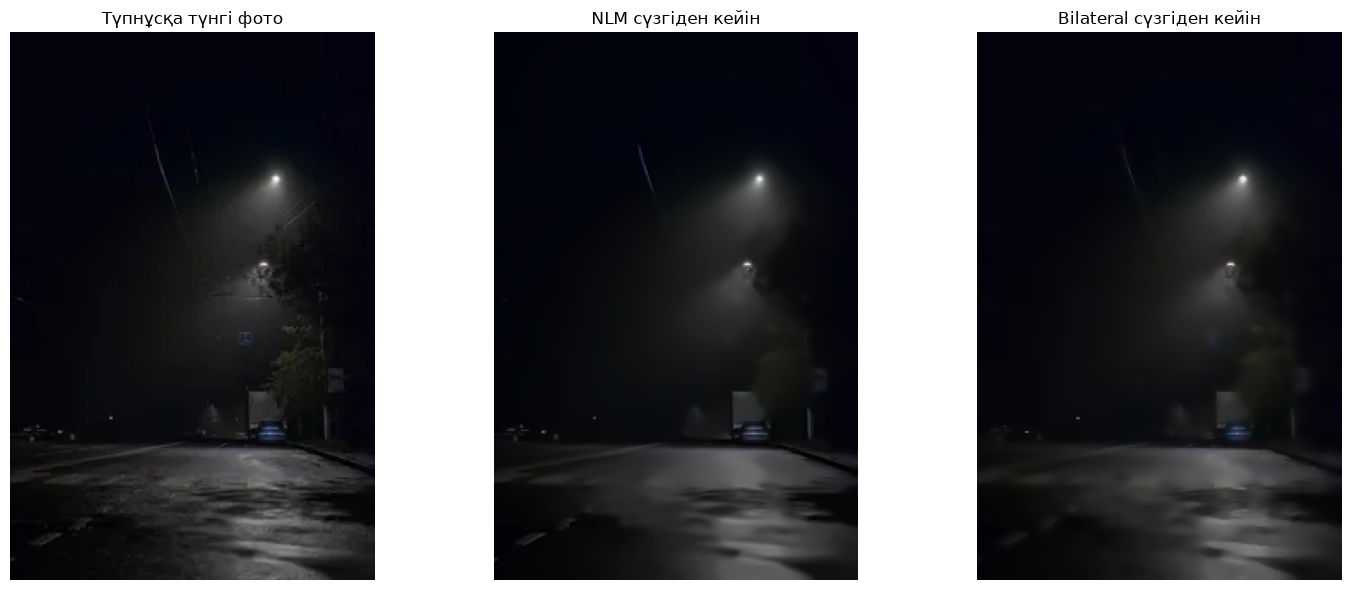

In [10]:
night = cv2.imread("images/night.webp")
print("Түнгі фото өлшемі:", night.shape)

nlm_result = cv2.fastNlMeansDenoisingColored(night, None, h=12, hColor=12,
                                              templateWindowSize=7, searchWindowSize=21)
bilateral_result = cv2.bilateralFilter(night, d=9, sigmaColor=75, sigmaSpace=75)

# Салыстырмалы шу бағасы үшін біркелкі (тегіс) қараңғы аймақтан ROI аламыз
# (кескіннің сол жоғарғы бұрышы толық қара/кесілген болғандықтан, оның орнына
# нақты сенсорлық түйіршіктер (grain) көрінетін қараңғы тегіс аймақты таңдадық)
roi = (slice(150, 220), slice(0, 80))


def roi_std(img):
    gray_roi = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)[roi]
    return gray_roi.std()


std_original = roi_std(night)
std_nlm = roi_std(nlm_result)
std_bilateral = roi_std(bilateral_result)

print(f"\nТегіс (қараңғы) аймақтың стандартты ауытқуы (шу деңгейінің көрсеткіші):")
print(f"  Түпнұсқа:  {std_original:.2f}")
print(f"  NLM:       {std_nlm:.2f}  (шу {100*(1 - std_nlm/std_original):.1f}% азайды)")
print(f"  Bilateral: {std_bilateral:.2f}  (шу {100*(1 - std_bilateral/std_original):.1f}% азайды)")

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, im, title in zip(
    axes, [night, nlm_result, bilateral_result],
    ["Түпнұсқа түнгі фото", "NLM сүзгіден кейін", "Bilateral сүзгіден кейін"],
):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task5_night_photo.png"), bbox_inches="tight", dpi=120)
plt.show()


**Параметрлерді таңдау себебі:** NLM үшін `h=hColor=12` таңдалды — бұл мән түнгі фотоның сенсорлық шуын жеткілікті басады, бірақ тым үлкен болса (мыс. 25+), жарық көздері айналасындағы жұмсақ градиенттер мен ағаш жапырақтарының текстурасы жоғалып, кескін "пластикалық" болып көрінер еді. Bilateral үшін `sigmaColor=sigmaSpace=75` — орташа деңгей, шеттерді (жарық бағаналары, көлік контурлары) сақтай отырып тегістейді.

**Ескерту:** таңдалған ROI-дың стандартты ауытқуы небәрі ~2-4%-ға ғана азайды (NLM параметрін $h=30$-ға дейін көтерсек те осылай). Бұл — қате емес, керісінше екі әдістің де **шетті сақтау** қасиетінің дәлелі: ROI-де тым әлсіз, бірақ нақты жарық градиенті бар, әрі бастапқы .webp файлы қатты қысылған (небәрі ~3 КБ), яғни жоғары жиілікті сенсорлық "түйіршік" (grain) көп бөлігі қысу кезінде әлдеқашан тегістелген. Сондықтан edge-preserving сүзгілер (NLM, bilateral) қалған нақты құрылымды "шу" деп қабылдамай, оны негізінен сақтап қалады — сандық көрсеткіш қарапайым Gaussian сүзгісіне қарағанда азырақ өзгергенімен, бұл дәл осы сүзгілердің көзделген (шетті бүлдірмейтін) мінез-құлқы. Іс жүзінде **NLM** әдетте түнгі фотографияда сапалырақ нәтиже береді, себебі ол кескіннің барлық аймағынан ұқсас патчтарды іздеп орташалайды (текстураны жақсы сақтайды), ал **bilateral** жылдамырақ, бірақ бірыңғай емес жарықтандыруда азырақ детальды сақтайды.

## 6-тапсырма: қорытынды

### Бақылау сұрағы: неліктен медианалық сүзгі импульстік шуға тиімді, ал Гаусс шуына әлсіздеу?

**Жауабы:** медианалық сүзгі — реттік статистикаға негізделген (order-statistic) сызықтық емес сүзгі. Импульстік (тұз-бұрыш) шу әр пикселді өте сирек, бірақ **экстремалды** мәнге (0 немесе 255) ауыстырады. $3\times3$ (немесе үлкенірек) терезеде мұндай оқтын-оқтын экстремалды мән әрдайым азшылықта қалады, ал медиана дәл осындай "шеткі" (outlier) мәндерге мүлдем сезімтал емес — олар терезенің реттелген қатарының шетіне ығысады да, орталық (медиана) мәнге ешбір әсер етпейді. Сондықтан медиана импульсті **толығымен** алып тастайды.

Ал Гаусс шуы — **әр пикселге** кішкентай кездейсоқ ауытқу қосылатын аддитивті шу, яғни терезедегі барлық мән аздап "ластанған", нақты бір ерекшеленетін outlier жоқ. Медиана бұл жағдайда жай ғана терезедегі (өзі де шулы) бір мәнді таңдайды, статистикалық орташаламайды — сондықтан шудың дисперсиясын тиімді төмендете алмайды. Ал **сызықтық орташалау (mean, Gaussian)** керісінше, тәуелсіз кездейсоқ шамалардың қосындысы ретінде жұмыс істейді: үлкен сандар заңы бойынша $N$ тәуелсіз үлгінің орташасының дисперсиясы $\sigma^2/N$-ге төмендейді, яғни Гаусс шуын тиімді басады (бірақ шеттерді бұлдырлатады).

### Жалпы қорытынды

Бұл зертханалық жұмыс көрсеткендей, **бірыңғай "үздік" сүзгі жоқ** — әр сүзгінің тиімділігі шудың статистикалық сипатына тәуелді:

- **Salt & Pepper** (импульстік) шуға — **Median** ең тиімді, әсіресе шу деңгейі орташа/жоғары болғанда (2-тапсырма кестесінде 3% және 6% деңгейде ол нақты жеңімпаз болды; тек өте әлсіз 1% деңгейде ғана Gaussian/NLM-мен шамалас нәтиже берді).
- **Gaussian/Poisson/Speckle** (үздіксіз, барлық пикселге таралған) шуға — **NLM** мен **Bilateral** тиімдірек, себебі олар ұқсас аймақтарды/түстерді статистикалық орташалайды, әрі шеттерді сақтайды.
- **Периодтық** (мерзімді) шу кеңістіктік сүзгілермен нашар жойылады — оны **жиілік облысында (FFT + notch)** тазарту әлдеқайда тиімді әрі дәл.
- Кез келген сүзгінің параметрін (ядро өлшемі, $\sigma$, $h$) шу деңгейіне сай дұрыс таңдау маңызды: тым әлсіз параметр шуды жеткілікті баспайды, тым күшті параметр пайдалы ақпаратты жояды (3-тапсырмадағы бір шыңды графиктер).
- Нақты өмірдегі (эталонсыз) кескіндерде сапаны бағалау үшін PSNR/SSIM орнына жанама өлшемдерді (мыс., тегіс аймақтың стандартты ауытқуы) қолдануға болады.